# 🌳 شجرة القرار من الصفر (Play Tennis)

هنطبّق اللي ذاكرته في ملاحظاتك بالكود:

1. نحسب **الـ Entropy** بإيدينا ونتأكد من أرقامك (0.940 / 0.811 / 1).
2. نحسب **الـ Information Gain** لكل عمود ونختار الـ root.
3. نبني الشجرة كلها بخوارزمية **ID3** (بدون أي مكتبة).
4. نقارنها بـ **sklearn**.
5. **Gini** بدل Entropy.
6. **Overfitting**: ليه الشجرة العميقة بتحفظ.

> الداتا هنا هي النسخة **الكلاسيكية (14 يوم)**. وفي الآخر هنقارنها بجدولك إنت (13 يوم) ونشوف الفرق.

In [1]:
import math, numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter

rows = '''Sunny Hot High Weak No
Sunny Hot High Strong No
Overcast Hot High Weak Yes
Rainy Mild High Weak Yes
Rainy Cool Normal Weak Yes
Rainy Cool Normal Strong No
Overcast Cool Normal Strong Yes
Sunny Mild High Weak No
Sunny Cool Normal Weak Yes
Rainy Mild Normal Weak Yes
Sunny Mild Normal Strong Yes
Overcast Mild High Strong Yes
Overcast Hot Normal Weak Yes
Rainy Mild High Strong No'''
cols = ["Outlook", "Temp", "Humidity", "Wind", "Play"]
df = pd.DataFrame([r.split() for r in rows.split("\n")], columns=cols)
df.index = df.index + 1; df.index.name = "Day"
df

,Outlook,Temp,Humidity,Wind,Play
Day,,,,,
1,Sunny,Hot,High,Weak,No
2,Sunny,Hot,High,Strong,No
3,Overcast,Hot,High,Weak,Yes
4,Rainy,Mild,High,Weak,Yes
5,Rainy,Cool,Normal,Weak,Yes
6,Rainy,Cool,Normal,Strong,No
7,Overcast,Cool,Normal,Strong,Yes
8,Sunny,Mild,High,Weak,No
9,Sunny,Cool,Normal,Weak,Yes


## 1) الـ Entropy

$$E(S) = -\sum_i p_i \log_2 p_i$$

- **0** = كل الصفوف نفس الفئة (نقي تمامًا).
- **1** = 50/50 (أكبر فوضى لفئتين).

خلينا نكتبها ونتأكد من أرقام ملاحظاتك:

In [2]:
def entropy(counts):
    n = sum(counts)
    return max(0.0, -sum(c / n * math.log2(c / n) for c in counts if c > 0))

print("E(9 yes, 5 no) =", round(entropy([9, 5]), 3), "  <- الـ root. ولاحظ إنها 0.940 مش 0.954")
print("E(6 yes, 2 no) =", round(entropy([6, 2]), 3), "  <- Wind=Weak")
print("E(3 yes, 3 no) =", round(entropy([3, 3]), 3), "  <- Wind=Strong")
print("E(10, 6)       =", round(entropy([10, 6]), 3), "  <- ده اللي طلع 0.954 (مثال الـ 16 عنصر)")

E(9 yes, 5 no) = 0.94   <- الـ root. ولاحظ إنها 0.940 مش 0.954
E(6 yes, 2 no) = 0.811   <- Wind=Weak
E(3 yes, 3 no) = 1.0   <- Wind=Strong
E(10, 6)       = 0.954   <- ده اللي طلع 0.954 (مثال الـ 16 عنصر)


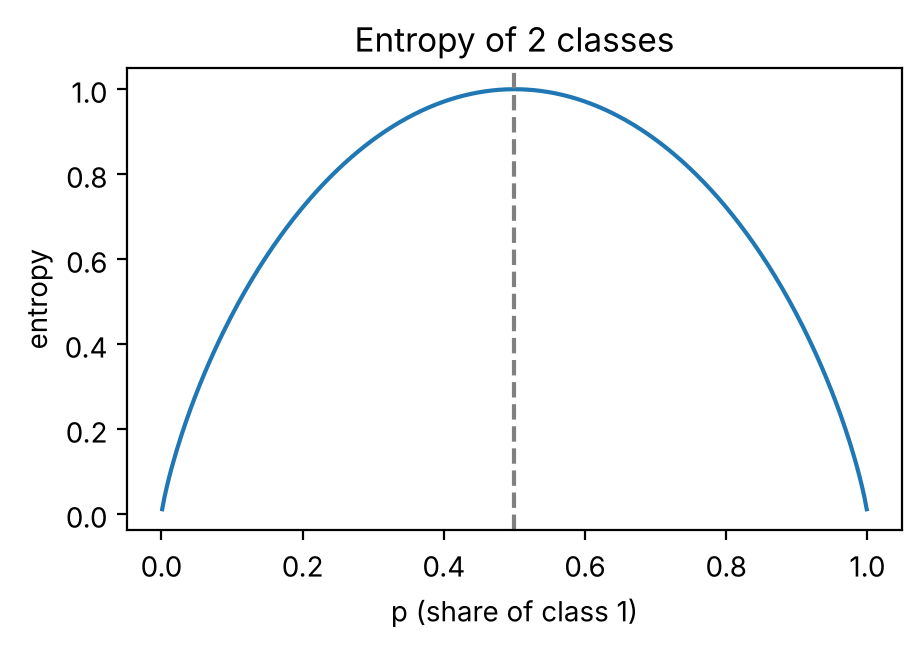

In [3]:
p = np.linspace(0.001, 0.999, 300)
plt.figure(figsize=(5, 3))
plt.plot(p, [entropy([x, 1 - x]) for x in p]); plt.axvline(0.5, ls="--", c="gray")
plt.xlabel("p (share of class 1)"); plt.ylabel("entropy"); plt.title("Entropy of 2 classes"); plt.show()

الأقصى (1) عند p = 0.5، وبيقع لـ 0 لما p = 0 أو 1. دي نفس الملاحظة اللي كتبتها: *أحسن نتيجة zero وأسوأ نتيجة 1*.

## 2) الـ Information Gain واختيار الـ root

$$G(S, A) = E(S) - \sum_v \frac{|S_v|}{|S|} E(S_v)$$

بنسأل: **لو قسّمت على العمود ده، الفوضى بتقل قد إيه؟** نحسبها لكل عمود.

Outlook     0.247
Humidity    0.152
Wind        0.048
Temp        0.029
dtype: float64


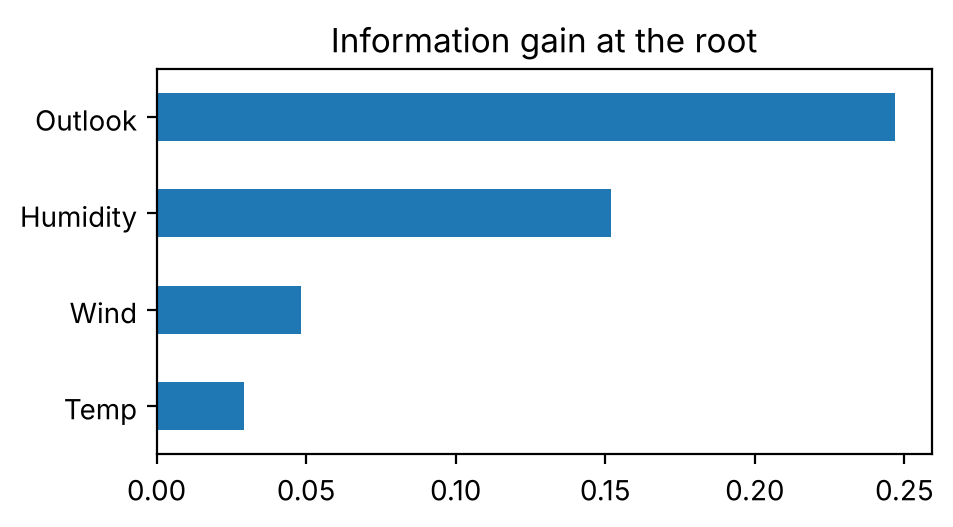

In [4]:
def entropy_of(series):
    return entropy(list(Counter(series).values()))

def info_gain(data, feature, target="Play"):
    total = entropy_of(data[target])
    remainder = sum(len(sub) / len(data) * entropy_of(sub[target]) for _, sub in data.groupby(feature))
    return total - remainder

features = ["Outlook", "Temp", "Humidity", "Wind"]
gains = pd.Series({f: info_gain(df, f) for f in features}).sort_values(ascending=False)
print(gains.round(3))
gains.plot.barh(figsize=(5, 2.5), title="Information gain at the root").invert_yaxis(); plt.show()

أعلى gain هو **Outlook** → هو الـ root. وده نفس ترتيب أرقامك: الـ Wind طلع 0.048 زي ما حسبته.

خلينا نشوف ليه Outlook بالذات، بتقسيمه:

In [5]:
for value, sub in df.groupby("Outlook"):
    print(f"Outlook = {value:9s} -> {dict(Counter(sub.Play))}   entropy = {entropy_of(sub.Play):.3f}")

Outlook = Overcast  -> {'Yes': 4}   entropy = 0.000
Outlook = Rainy     -> {'Yes': 3, 'No': 2}   entropy = 0.971
Outlook = Sunny     -> {'No': 3, 'Yes': 2}   entropy = 0.971


**Overcast** كله Yes → entropy = 0 → ده **ورقة** (نخلّص ونقول Yes). الباقي (Sunny / Rainy) لسه مختلط ونكمّل عليه بنفس الطريقة (recursion).

In [6]:
for value in ("Sunny", "Rainy"):
    sub = df[df.Outlook == value]
    g = {f: round(info_gain(sub, f), 3) for f in ["Temp", "Humidity", "Wind"]}
    print(f"داخل Outlook={value}:", g)

داخل Outlook=Sunny: {'Temp': 0.571, 'Humidity': 0.971, 'Wind': 0.02}
داخل Outlook=Rainy: {'Temp': 0.02, 'Humidity': 0.02, 'Wind': 0.971}


جوّه **Sunny** الأفضل Humidity (gain = 0.971 يعني بيفصل تمام). وجوّه **Rainy** الأفضل Wind. كده الشجرة اتحددت.

## 3) ID3: الشجرة كلها بدون مكتبات

الفكرة (recursion):
1. لو كل الصفوف نفس الفئة → ورقة.
2. لو مفيش أعمدة تانية → ورقة بالفئة الأكتر.
3. غير كده → اختار العمود بأعلى gain وقسّم، وكرر على كل جزء.

In [7]:
def id3(data, feats, target="Play"):
    y = data[target]
    if y.nunique() == 1:
        return y.iloc[0]
    if not feats:
        return y.mode()[0]
    best = max(feats, key=lambda f: info_gain(data, f, target))
    rest = [f for f in feats if f != best]
    return {best: {v: id3(sub, rest, target) for v, sub in data.groupby(best)}}

tree = id3(df, features)

def show(node, indent=""):
    if not isinstance(node, dict):
        print(indent + "->", node); return
    (feat, branches), = node.items()
    for v, child in branches.items():
        if isinstance(child, dict):
            print(f"{indent}{feat} = {v}:"); show(child, indent + "    ")
        else:
            print(f"{indent}{feat} = {v}: {child}")
show(tree)

Outlook = Overcast: Yes
Outlook = Rainy:
    Wind = Strong: No
    Wind = Weak: Yes
Outlook = Sunny:
    Humidity = High: No
    Humidity = Normal: Yes


In [8]:
def predict(node, row):
    while isinstance(node, dict):
        (feat, branches), = node.items()
        node = branches.get(row[feat])
        if node is None:
            return None      # قيمة عمر الشجرة ما شافتها
    return node

pred = df.apply(lambda r: predict(tree, r), axis=1)
print("accuracy على نفس الداتا اللي اتدرّبت عليها:", (pred == df.Play).mean())
print("يوم جديد (Sunny, Mild, High, Weak):", predict(tree, {"Outlook": "Sunny", "Temp": "Mild", "Humidity": "High", "Wind": "Weak"}))

accuracy على نفس الداتا اللي اتدرّبت عليها: 1.0
يوم جديد (Sunny, Mild, High, Weak): No


الـ accuracy = 1.0 على داتا التدريب. **ده مش معناه إنها ممتازة**، معناه إنها **حفظت** الداتا (شجرة كاملة لحد ما كل ورقة بتبقى نقية). هنرجع للنقطة دي في القسم 6.

## 4) نفس الشيء بـ sklearn

الفرق الشكلي: sklearn بيحتاج أرقام، فبنحوّل كل قيمة لعمود 0/1 (one-hot)، وكل تقسيمة عنده **ثنائية** (أقل من أو يساوي 0.5) مش متعددة زي ID3.

|--- Outlook_Overcast <= 0.50
|   |--- Humidity_Normal <= 0.50
|   |   |--- Outlook_Rainy <= 0.50
|   |   |   |--- class: No
|   |   |--- Outlook_Rainy >  0.50
|   |   |   |--- Wind_Strong <= 0.50
|   |   |   |   |--- class: Yes
|   |   |   |--- Wind_Strong >  0.50
|   |   |   |   |--- class: No
|   |--- Humidity_Normal >  0.50
|   |   |--- Wind_Weak <= 0.50
|   |   |   |--- Temp_Cool <= 0.50
|   |   |   |   |--- class: Yes
|   |   |   |--- Temp_Cool >  0.50
|   |   |   |   |--- class: No
|   |   |--- Wind_Weak >  0.50
|   |   |   |--- class: Yes
|--- Outlook_Overcast >  0.50
|   |--- class: Yes



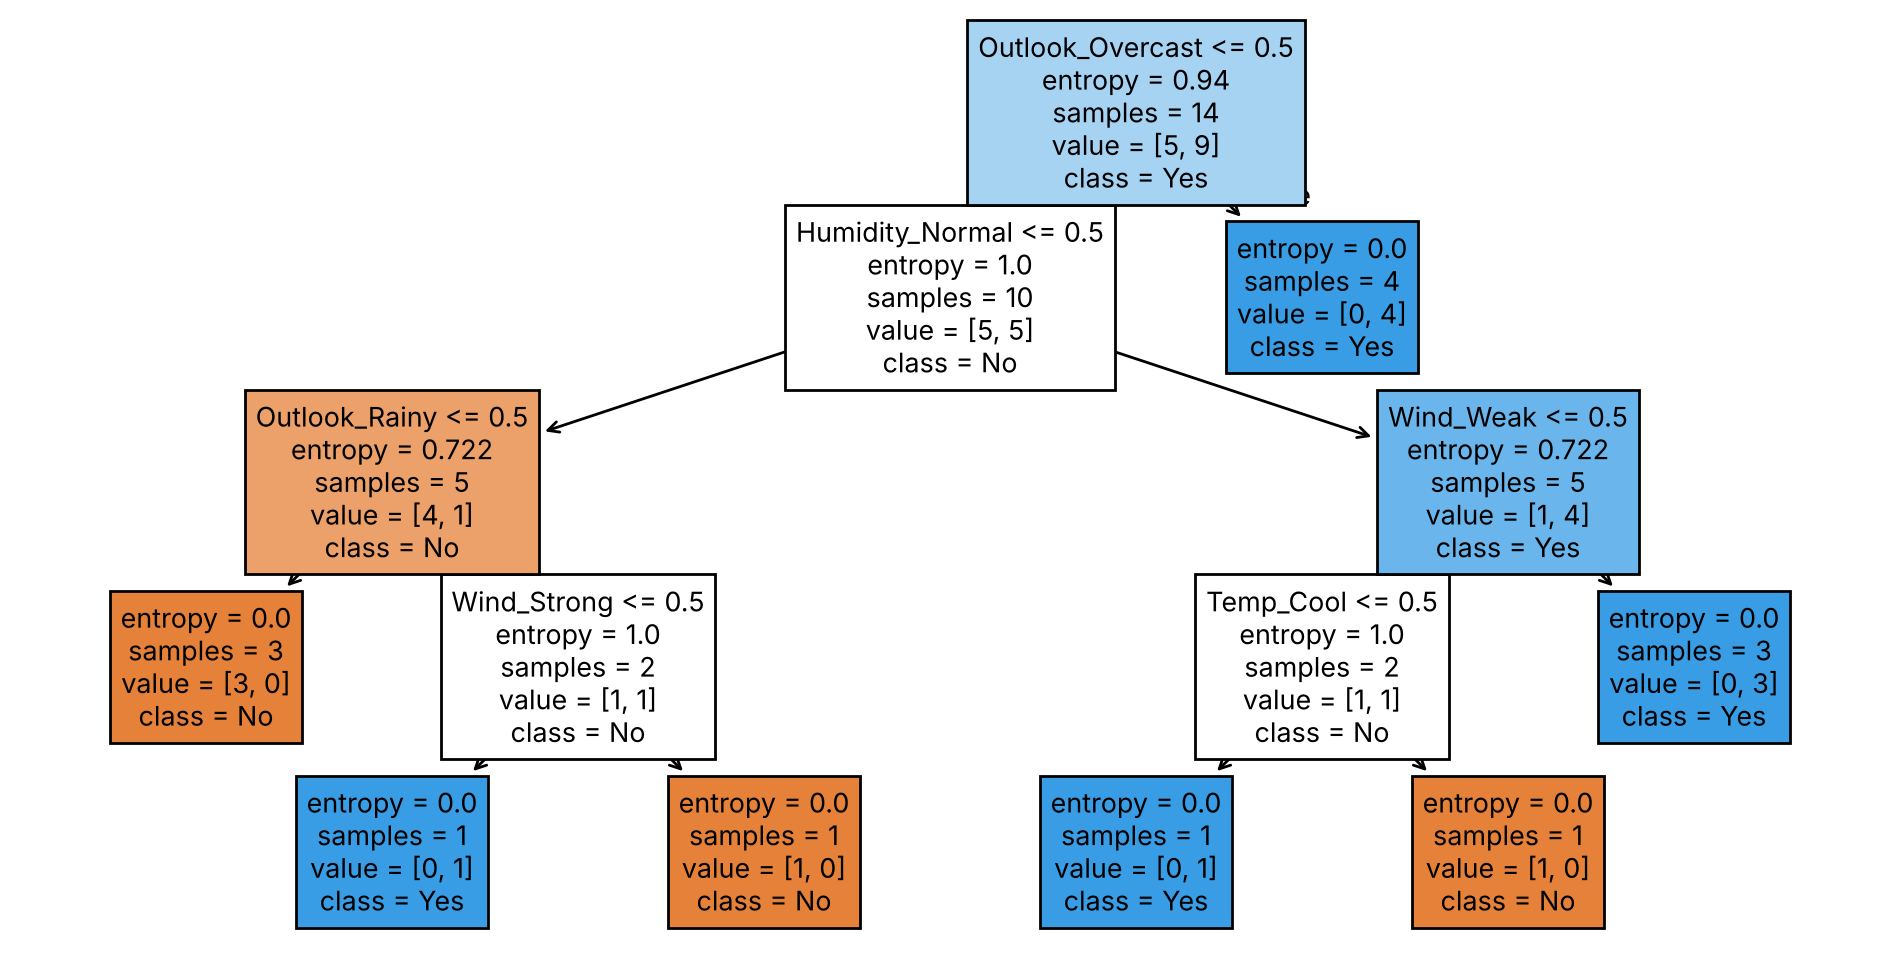

In [9]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
X = pd.get_dummies(df[features]).astype(int)
clf = DecisionTreeClassifier(criterion="entropy", random_state=0).fit(X, df.Play)
print(export_text(clf, feature_names=list(X.columns)))
plt.figure(figsize=(12, 6)); plot_tree(clf, feature_names=list(X.columns), class_names=list(clf.classes_), filled=True, impurity=True); plt.show()

الشجرة شكلها مختلف (لأن التقسيم ثنائي) لكن **الفكرة نفسها**: بدأت بـ `Outlook_Overcast` اللي بيعزل الفرع النقي. لاحظ الـ `entropy = 0.940` في الـ root في الرسمة: ده نفس رقمك الصح.

## 5) Gini بدل Entropy

$$Gini(S) = 1 - \sum_i p_i^2$$

بيقيس نفس الفكرة (النقاء) بمعادلة أبسط (من غير log). هو **الافتراضي في sklearn** (`criterion="gini"`).

In [10]:
def gini(counts):
    n = sum(counts); return 1 - sum((c / n) ** 2 for c in counts)

def gini_gain(data, feature, target="Play"):
    g = lambda s: gini(list(Counter(s).values()))
    return g(data[target]) - sum(len(sub) / len(data) * g(sub[target]) for _, sub in data.groupby(feature))

cmp = pd.DataFrame({"entropy gain": {f: info_gain(df, f) for f in features},
                    "gini gain": {f: gini_gain(df, f) for f in features}}).round(3)
cmp.sort_values("entropy gain", ascending=False)

,entropy gain,gini gain
Outlook,0.247,0.116
Humidity,0.152,0.092
Wind,0.048,0.031
Temp,0.029,0.019


الأرقام مختلفة لكن **الترتيب نفسه** (Outlook ثم Humidity ثم Wind ثم Temp). عمليًا الاتنين بيدّوا أشجار شبه بعض. الـ entropy أبطأ شوية لأن فيه log.

## 6) Overfitting: ليه الشجرة العميقة بتحفظ؟

لو سبناها تكمّل لحد ما كل ورقة نقية، بتحفظ حتى الـ **noise**. الحل: نحدّ عمقها (`max_depth`) أو نقول أقل عدد صفوف في الورقة (`min_samples_leaf`). نجرّبها على داتا الأكواد من النوت بوك اللي فات (لو الملف جنب النوت بوك ده).

,max_depth,train PR-AUC,test PR-AUC
0,1,0.065,0.004
1,2,0.256,0.004
2,3,0.382,0.017
3,5,0.619,0.080
4,8,0.867,0.230
5,12,0.986,0.569
6,20,0.998,0.331
7,None,1.000,0.355


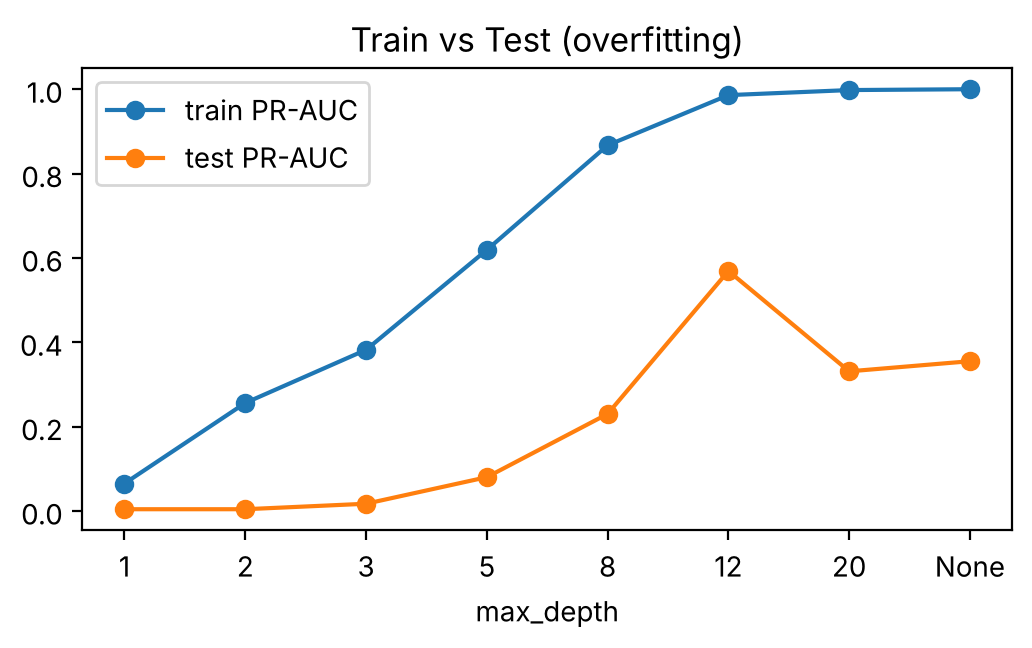

In [11]:
import os
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import average_precision_score

if not os.path.exists("code_units.csv"):
    print("حط code_units.csv جنب النوت بوك ده عشان تشوف الجزء ده.")
else:
    code_df = pd.read_csv("code_units.csv")
    seed_idx = np.where(code_df.source == "seed")[0]; real_idx = np.where(code_df.source == "stdlib")[0]
    real = code_df.iloc[real_idx]
    a_, b_ = next(StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=0).split(real.text, real.label, groups=real.group))
    tr, te = np.concatenate([seed_idx, real_idx[a_]]), real_idx[b_]

    cv = CountVectorizer(token_pattern=r"[A-Za-z_][A-Za-z_0-9]*|[+%*=,]", ngram_range=(1, 2), min_df=5, binary=True, max_features=3000)
    Xtr = cv.fit_transform(code_df.text.iloc[tr]); Xte = cv.transform(code_df.text.iloc[te])
    ytr, yte = code_df.label.iloc[tr], code_df.label.iloc[te]

    rows_ = []
    for depth in (1, 2, 3, 5, 8, 12, 20, None):
        t = DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=0).fit(Xtr, ytr)
        rows_.append((str(depth), average_precision_score(ytr, t.predict_proba(Xtr)[:, 1]), average_precision_score(yte, t.predict_proba(Xte)[:, 1])))
    res = pd.DataFrame(rows_, columns=["max_depth", "train PR-AUC", "test PR-AUC"]).round(3)
    display(res)
    res.set_index("max_depth").plot(marker="o", figsize=(6, 3), title="Train vs Test (overfitting)"); plt.show()

**اقرا الرسمة:** منحنى الـ train بيطلع لـ 1 (بيحفظ) ومنحنى الـ test بيقف أو بينزل. الفجوة بينهم هي الـ overfitting. أحسن عمق هو اللي عنده أعلى **test**، مش أعلى train.

> دي نفس سبب إن الـ Decision Tree طلع أضعف من الانحدار اللوجستي في النوت بوك اللي فات، وسبب إن **Random Forest** اتخلق: بيجمع مئات أشجار وبياخد تصويتها فبيقلّل الحفظ.

## 7) قارن مع جدولك إنت (13 يوم)

دي نسختك كما قرأتها من الصورة. **راجعها مع الأصل وصلّح اللي غلط**، وبعدين شوف الفرق في النتايج.

In [12]:
mine_rows = '''Sunny Hot High Weak No
Sunny Hot High Strong No
Overcast Hot High Weak Yes
Rainy Mild High Weak Yes
Rainy Cool Normal Weak Yes
Rainy Cool Normal Strong No
Overcast Cool Normal Weak Yes
Sunny Mild High Weak No
Sunny Cool Normal Weak Yes
Rainy Mild Normal Strong Yes
Sunny Mild Normal Strong Yes
Overcast Mild High Strong Yes
Rainy Mild High Strong No'''
mine = pd.DataFrame([r.split() for r in mine_rows.split("\n")], columns=cols); mine.index += 1

print("E(S) جدولك:", round(entropy_of(mine.Play), 3), "| كلاسيكي:", round(entropy_of(df.Play), 3))
pd.DataFrame({"جدولك (13)": {f: info_gain(mine, f) for f in features},
              "كلاسيكي (14)": {f: info_gain(df, f) for f in features}}).round(3)

E(S) جدولك: 0.961 | كلاسيكي: 0.94


,جدولك (13),كلاسيكي (14)
Outlook,0.214,0.247
Temp,0.076,0.029
Humidity,0.131,0.152
Wind,0.035,0.048


الفروق اللي لاحظتها في الصورة: يوم 7 و10 (قيمة Wind)، وصف ناقص (Overcast / Hot / Normal / Weak / Yes). غيّر `mine_rows` للقيم الصح وشوف الـ gain بيرجع 0.048 ولا لأ.

## 🎯 تمارين
1. صلّح `mine_rows` عشان يطابق جدولك الأصلي، وتأكد إن `Gain(Wind)` بيطلع 0.048.
2. غيّر `entropy` لـ `gini` جوه `id3` وشوف الشجرة بتتغير ولا لأ.
3. ضيف عمود جديد `Day` (1 لـ 14) واحسب الـ gain بتاعه. إيه اللي بيحصل؟ ليه؟ (تلميح: **عمود فيه قيمة مختلفة لكل صف** بيدّي gain عالي وهو عديم الفايدة).
4. جرّب `min_samples_leaf=3` في القسم 6 وقارن.
5. اشرح بكلامك: ليه الـ Random Forest بيقلّل الـ overfitting؟

In [2]:
def best_split_1d(x, y):
    xs = np.sort(np.unique(x))
    parent = gini(y)
    best = {"t": None, "gain": 0.0, "w": parent}
    for t in (xs[:-1] + xs[1:]) / 2:
        left, right = y[x <= t], y[x > t]
        w = (len(left) * gini(left) + len(right) * gini(right)) / len(y)
        if w < best["w"] - 1e-12:       # strictly better فقط → أول تعادل يكسب
            best = {"t": t, "gain": parent - w, "w": w}
    return best

print(best_split_1d(x, y))

{'t': np.float64(3.5), 'gain': np.float64(0.25), 'w': np.float64(0.25)}
